#

# Kalbe Take Home Test
Name: Riccy Riandy intan

## Focus:
Who Brings the Revenue, Who Are We Losing, and When Should We Prepare?


### Questions:
A UK online wholesaler of giftware sells to many small businesses. Three decisions depend on data:
1. Who generates the revenue, and which customers are slipping away?
2. When does demand peak, and which products drive it?
3. What should we do differently for each type of customer?


### Approach:
1. Explore and clean the data, and record every cleaning decision, since wrong data gives confident but wrong answers
2. Look at sales over time and by product to find seasonal trends
3. Describe each customer with LRFM and group similar customers with K-means, since it is simple, explainable, and something many are familiar of (LRFM)
4. Turn the groups into actions

In [260]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [261]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [262]:
data = pd.read_csv("/content/drive/MyDrive/online_retail_II.csv")
print(data.shape)

(1067371, 8)


# EDA & Data Cleaning
Understanding the characteristics of data before deciding what do to for cleaning and pre-processing

In [263]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


1. Show the data types for each attributes. This helps in determining in how we can process the data in the future
2. Gives clue on NULL values. It shows that there are 1.067.371 data entries (rows), but some attributes (e.g. Customer ID and Description) have missing values.

In [264]:
# Check for duplicates
duplicated_values = data.duplicated().sum()

print(f"Duplicates: {duplicated_values}")

Duplicates: 34335


There are 34335 records that have the same exact data. Remove this, as this may provide an inaccurate representation for customer's LRFM

In [265]:
# Proportions of missing values
missing_data = pd.DataFrame({
    'Missing count': data.isnull().sum(),
    'Missing percentage (%)': (data.isnull().mean() * 100).round(2)
})

print(missing_data)

             Missing count  Missing percentage (%)
Invoice                  0                    0.00
StockCode                0                    0.00
Description           4382                    0.41
Quantity                 0                    0.00
InvoiceDate              0                    0.00
Price                    0                    0.00
Customer ID         243007                   22.77
Country                  0                    0.00


This piece of code have a function to show the number and proportion of missing values in the dataset.

This is useful to detect the mistakes, quality of data, and way forward (e.g. how to solve the problems detected? will we continue with this dataset? etc).

In this case, the variable with the most missing value is "Customer ID", with 22.77% of its data are missing, followed by "Description" with 0.41% of its data missing.

Preprocesing way forward: rows without Customer ID cannot be linked to a customer, so they are removed only for the customer segmentation (LRFM). They are real sales, so they are kept for the sales, product and seasonal analysis.

In [266]:
# Describing the data
data[['Quantity', 'Price']].describe()

,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


This is to know the statistical analysis of numerical data.
1. There are anomalies. "Quantity" contains negative values (based on the min values), meaning are data inaccuracy present. Logically, the quantity bought should not be negative. However, this may be caused by the cancelled orders.
2. "Quantity" is heavily right-skewed. The median is 3 and the mean is about 9.9, but the maximum is 80,995. Most purchases are small, but a few are very large (potential resellers or outliers).
3. "Price" is not balanced either. It runs from about -53,594 to 38,970, with a standard deviation of about 124 against a median of 2.10. A few extreme rows distort the mean, so negative and extreme prices are investigated below.
4. Both 'Price' and 'Quantity' both have a high standard deviation, meaning that the values are shown to have a high variability.

### Investigating negative values (Quantity)

In [267]:
# Check the source of negative quantity

invoice_negative_quantity = data[data["Quantity"] < 0]

invoice_negative_quantity_freq = len(invoice_negative_quantity)

cancelled_invoice_negative_quantity = invoice_negative_quantity[invoice_negative_quantity['Invoice'].str.startswith("C")]
cancelled_invoice_negative_quantity_freq = len(cancelled_invoice_negative_quantity)

print("")
print(f"Number of orders with negative quantity: {invoice_negative_quantity_freq}")
print(f"Number of cancelled orders with negative quantity: {cancelled_invoice_negative_quantity_freq}")


Number of orders with negative quantity: 22950
Number of cancelled orders with negative quantity: 19493


There are a difference between the invoice with negative quantity values with the number of cancelled invoice. This means there are a portion of invoice that have negative quantity values not because the invoice is cancelled.

In [268]:
# Count the other negative-quantity transaction rows
invoice_other_negative_quantity = invoice_negative_quantity[~invoice_negative_quantity['Invoice'].str.startswith("C")]
invoice_other_negative_quantity_freq = len(invoice_other_negative_quantity)

print(f"Number of other orders with negative quantity: {invoice_other_negative_quantity_freq}\n")

print(invoice_other_negative_quantity.head())

Number of other orders with negative quantity: 3457

     Invoice StockCode   Description  Quantity          InvoiceDate  Price  \
263   489464     21733  85123a mixed       -96  2009-12-01 10:52:00    0.0   
283   489463     71477         short      -240  2009-12-01 10:52:00    0.0   
284   489467    85123A   21733 mixed      -192  2009-12-01 10:53:00    0.0   
470   489521     21646           NaN       -50  2009-12-01 11:44:00    0.0   
3114  489655     20683           NaN       -44  2009-12-01 17:26:00    0.0   

      Customer ID         Country  
263           NaN  United Kingdom  
283           NaN  United Kingdom  
284           NaN  United Kingdom  
470           NaN  United Kingdom  
3114          NaN  United Kingdom  


In [269]:
# Check if the source of the 'other negative-quantity' is from missing cust ID
invoice_other_negative_quantity.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3457 entries, 263 to 1064386
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      3457 non-null   object 
 1   StockCode    3457 non-null   object 
 2   Description  768 non-null    object 
 3   Quantity     3457 non-null   int64  
 4   InvoiceDate  3457 non-null   object 
 5   Price        3457 non-null   float64
 6   Customer ID  0 non-null      float64
 7   Country      3457 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 243.1+ KB


This info shows that all negative-quantity rows have no Customer ID. The rows printed above also have a unit price of 0 and free-text descriptions such as "85123a". This pattern is consistent with internal stock adjustments (damaged, lost or miscounted goods), not with customer purchases.

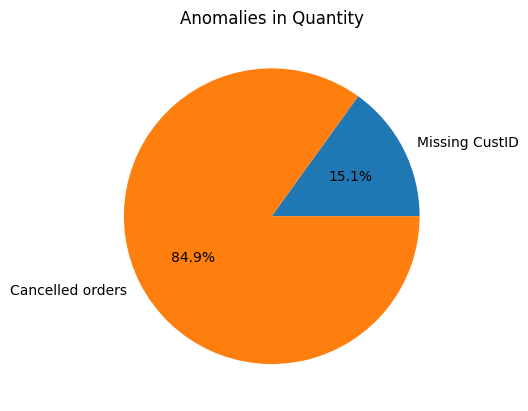

In [270]:
#  Visualization
quantity_anomalies_categories = ['Missing CustID', 'Cancelled orders']
quantity_anomalies_counts = [invoice_other_negative_quantity_freq, cancelled_invoice_negative_quantity_freq]

plt.pie(quantity_anomalies_counts, labels=quantity_anomalies_categories, autopct='%1.1f%%')
plt.title('Anomalies in Quantity')
plt.show()

Cause of negative quantities: cancelled orders (84.9%) and missing Customer ID (15.1%)

Preprocesing way forward:
1. 15.1% of the negative quantities will be removed, since the Customer ID are all missing.
2. 84.9% of the negative quantities will be removed, since cancelling orders meant the customers actively chose to not engage with the business; churn. Moreover, there the dataset does not give the reason why the customer cancelled their order, so it does not hold substantial value.

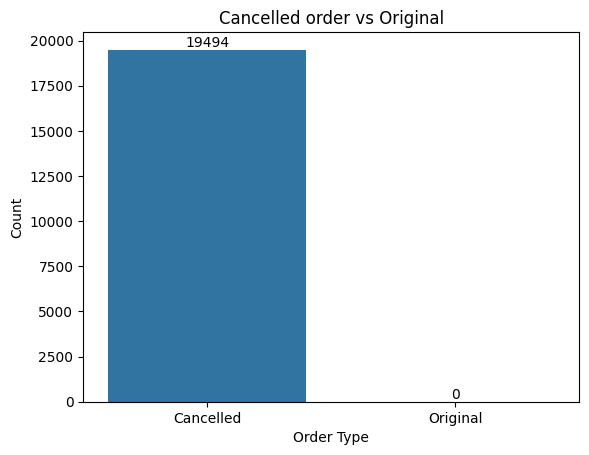

In [271]:
# See if cancelled order have their original invoice
cancelled_order = data[data['Invoice'].str.startswith('C')]
original_invoice = data[data['Invoice'].astype(str).isin(cancelled_order['Invoice'].astype(str).str[1:])]

cancelled_comparison = pd.DataFrame({
    'Order Type' : ['Cancelled', 'Original'],
    'Count' : [len(cancelled_order), len(original_invoice)]
})

cancelled_order_plot = sns.barplot(x='Order Type', y='Count', data=cancelled_comparison)
cancelled_order_plot.bar_label(cancelled_order_plot.containers[0])
plt.xlabel('Order Type')
plt.ylabel('Count')
plt.title("Cancelled order vs Original")
plt.show()

This shows that we only need to remove the cancelled invoice, since a cancelled invoice has no corresponding original invoice

### Investigating anomalies values (Price)

In [272]:
# Check the source of negative price

# Get transactions with negative price or 0
invoice_negative_price = data[data["Price"] < 0]
invoice_negative_price_freq = len(invoice_negative_price)

invoice_negative_price.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5 entries, 179403 to 825445
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      5 non-null      object 
 1   StockCode    5 non-null      object 
 2   Description  5 non-null      object 
 3   Quantity     5 non-null      int64  
 4   InvoiceDate  5 non-null      object 
 5   Price        5 non-null      float64
 6   Customer ID  0 non-null      float64
 7   Country      5 non-null      object 
dtypes: float64(2), int64(1), object(5)
memory usage: 360.0+ bytes


Preprocesing way forward: all the negative priced products will be removed, since the Customer ID are all missing.


In [273]:
# Understanding 0 prices

invoice_zero_price = data[data["Price"] == 0]

invoice_zero_price.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6202 entries, 263 to 1064386
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      6202 non-null   object 
 1   StockCode    6202 non-null   object 
 2   Description  1820 non-null   object 
 3   Quantity     6202 non-null   int64  
 4   InvoiceDate  6202 non-null   object 
 5   Price        6202 non-null   float64
 6   Customer ID  71 non-null     float64
 7   Country      6202 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 436.1+ KB


In [274]:
invoice_zero_price_stockcode = invoice_zero_price['StockCode'].unique()
summary_invoice_zero_price_stockcode = data[data['StockCode'].isin(invoice_zero_price_stockcode)].groupby('StockCode')['Price'].agg(['sum', 'min', 'median', 'max', pd.Series.mode])

print(summary_invoice_zero_price_stockcode.head(10))

              sum  min  median   max         mode
StockCode                                        
10002      391.66  0.0    0.85  1.70         0.85
10080       14.14  0.0    0.39  0.85         0.39
10109        0.42  0.0    0.21  0.42  [0.0, 0.42]
10120       18.58  0.0    0.21  0.43         0.21
10123C      53.12  0.0    0.65  1.30         0.65
10123G      14.01  0.0    0.65  1.70         0.65
10124A       7.98  0.0    0.42  0.42         0.42
10124C       0.00  0.0    0.00  0.00          0.0
10133      225.23  0.0    0.83  1.70         0.85
10134       73.45  0.0    1.25  2.57         1.25


From the table above, the product prices fluctuates, including 0. There are not enough information to explain this phenomenon. Reasons could span from:
1. Wrong input
2. Free gifts
3. Voucher discounts
4. etc.

A zero-price row carries no revenue, and we cannot tell whether it is a customer purchase. For this reason:

Preprocessing way forward: all rows with price 0 (and negative prices) are **removed from both analyses**, so that the sales analysis and the customer analysis follow the same rule. If not, some customers would end up with 0 spend.


### Boxplots of Quantity and Price

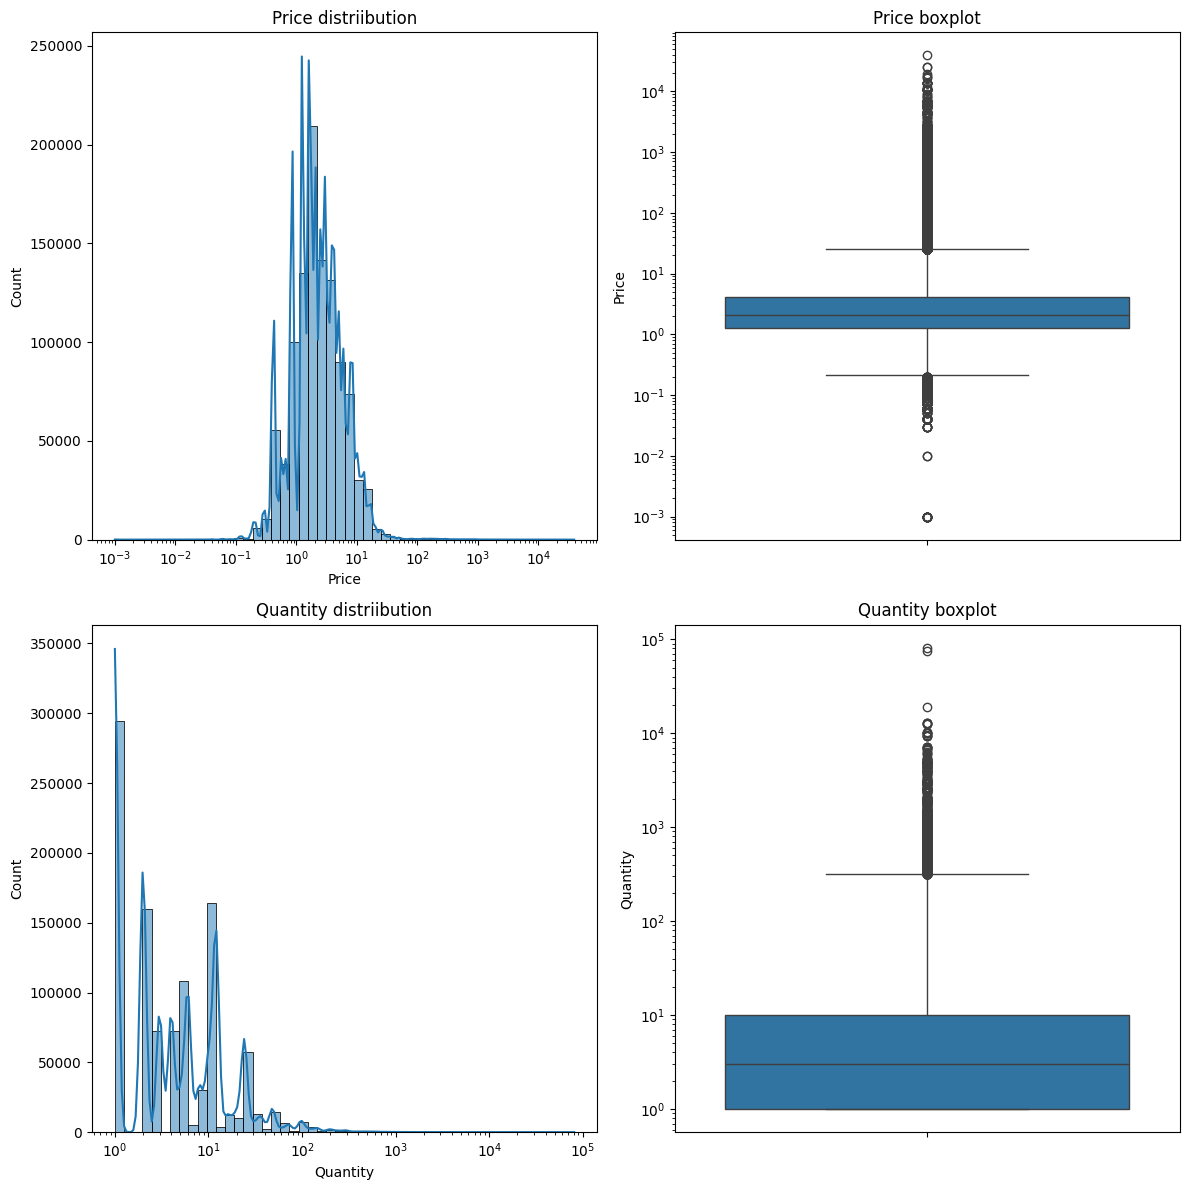

In [275]:
positive_quantity = data[data['Quantity'] > 0]['Quantity']
positive_price = data[data['Price'] > 0]['Price']

plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
sns.histplot(positive_price, bins=50, kde=True, log_scale=True)
plt.title("Price distriibution")

plt.subplot(2, 2, 2)
sns.boxplot(positive_price, log_scale=True)
plt.title("Price boxplot")

plt.subplot(2, 2, 3)
sns.histplot(positive_quantity, bins=50, kde=True, log_scale=True)
plt.title("Quantity distriibution")

plt.subplot(2, 2, 4)
sns.boxplot(positive_quantity, log_scale=True)
plt.title("Quantity boxplot")

plt.tight_layout()
plt.show()

In [276]:
# Check of there are any stockcodes that are not real, since real products have 5 digits
non_product = data[~data['StockCode'].astype(str).str.match(r'^\d{5}')]
display(non_product.groupby('StockCode')
        .agg(Rows=('Price', 'size'), Description=('Description', 'first'))
        .sort_values('Rows', ascending=False).head(15))
print(f"{len(non_product):,} rows ({len(non_product) / len(data):.2%}) have a non-product StockCode")

,Rows,Description
StockCode,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
C2,282,CARRIAGE
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE


6,093 rows (0.57%) have a non-product StockCode


In [277]:
# check what stockcode is expesive, because median price is 2 pounds.
expensive = (data[data['Price'] > 1000]
             .groupby('StockCode')
             .agg(Rows=('Price', 'size'), MaxPrice=('Price', 'max'), Description=('Description', 'first')))
display(expensive.sort_values('MaxPrice', ascending=False))

,Rows,MaxPrice,Description
StockCode,,,
M,166,38970.00,Manual
BANK CHARGES,2,18910.69,Bank Charges
AMAZONFEE,39,17836.46,AMAZON FEE
B,1,11062.06,Adjust bad debt
POST,2,8142.75,POSTAGE
ADJUST,1,5117.03,Adjustment by john on 26/01/2010 17
DOT,29,4505.17,DOTCOM POSTAGE
D,2,1867.86,Discount
84016,1,1157.15,FLAG OF ST GEORGE CAR FLAG


Log_scale are used because the Price and Quantity have a very high standard deviation

Price: Most products are cheap (median about 2 pounds). The long tail of very expensive rows is checked in the cell above: POST, DOT, etc. They will be removed, because they are not products and would change Monetary and product rankings.

Quantity: The histogram peaks at <100 units. This suggests many customers buy for resale. A few products exceed 10,000 units. Large quantities are kept, because they may be genuine reseller orders.

### Data Cleaning

In [278]:
# Remove duplicates
data = data.drop_duplicates()

In [279]:
# Flags and revenue
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data['IsCancel'] = data['Invoice'].astype(str).str.startswith('C')

# Real product codes start with 5 digits
data['IsProduct'] = data['StockCode'].astype(str).str.match(r'^\d{5}')
data['Revenue'] = data['Quantity'] * data['Price']

# Cancelled orders
cancel_rows = data['IsCancel']
data.loc[cancel_rows, 'Revenue'] = -data.loc[cancel_rows, 'Quantity'].abs() * data.loc[cancel_rows, 'Price']

# real products with a positive price
base = data[data['IsProduct'] & (data['Price'] > 0)]

# for time and seasonal analysis
sales_all = base[~base['IsCancel'] & (base['Quantity'] > 0)].copy()

# for product rankings so cancelled orders disappear
sales_net = base[base['IsCancel'] | (base['Quantity'] > 0)].copy()

# data_lrfm needs Customer ID
data_lrfm = base[base['Customer ID'].notna()].copy()

sales_all is used for monthly revenue and seasonality.

sales_net is used for product rankings, so cancelled orders no longer inflate the bestsellers.

data_lrfm is used to segment the customers.

In [280]:
# Remove records with Customer ID
data_lrfm = base[base['Customer ID'].notna()].copy()

segmenting the customers requires customer ID, meanwhile analyzing sales statistics does not

In [281]:
# Remove cancelled orders
sales_all = sales_all[~sales_all['Invoice'].str.startswith('C')]
data_lrfm = data_lrfm[~data_lrfm['Invoice'].str.startswith('C')]

In [282]:
sales_all.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1003214 entries, 0 to 1067369
Data columns (total 11 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1003214 non-null  object        
 1   StockCode    1003214 non-null  object        
 2   Description  1003214 non-null  object        
 3   Quantity     1003214 non-null  int64         
 4   InvoiceDate  1003214 non-null  datetime64[ns]
 5   Price        1003214 non-null  float64       
 6   Customer ID  776577 non-null   float64       
 7   Country      1003214 non-null  object        
 8   IsCancel     1003214 non-null  bool          
 9   IsProduct    1003214 non-null  bool          
 10  Revenue      1003214 non-null  float64       
dtypes: bool(2), datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 78.5+ MB


In [283]:
data_lrfm.info()

<class 'pandas.core.frame.DataFrame'>
Index: 776577 entries, 0 to 1067369
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      776577 non-null  object        
 1   StockCode    776577 non-null  object        
 2   Description  776577 non-null  object        
 3   Quantity     776577 non-null  int64         
 4   InvoiceDate  776577 non-null  datetime64[ns]
 5   Price        776577 non-null  float64       
 6   Customer ID  776577 non-null  float64       
 7   Country      776577 non-null  object        
 8   IsCancel     776577 non-null  bool          
 9   IsProduct    776577 non-null  bool          
 10  Revenue      776577 non-null  float64       
dtypes: bool(2), datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 60.7+ MB


In [284]:
print(sales_all.duplicated().sum())
print(data_lrfm.duplicated().sum())

0
0


In [285]:
sales_all.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,1.003214e+06,1003214,1.003214e+06,776577.000000,1.003214e+06
mean,1.115193e+01,2011-01-04 12:09:17.149522176,3.339875e+00,15326.605797,1.957976e+01
min,1.000000e+00,2009-12-01 07:45:00,3.000000e-02,12346.000000,6.000000e-02
25%,1.000000e+00,2010-07-06 12:01:00,1.250000e+00,13979.000000,4.130000e+00
50%,4.000000e+00,2010-12-09 16:00:30,2.100000e+00,15253.000000,1.008000e+01
75%,1.200000e+01,2011-07-28 14:03:00,4.130000e+00,16795.000000,1.770000e+01
max,8.099500e+04,2011-12-09 12:50:00,1.157150e+03,18287.000000,1.684696e+05
std,1.287471e+02,NaN,4.754713e+00,1692.861742,1.999959e+02


In [286]:
data_lrfm.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,776577.000000,776577,776577.000000,776577.000000,776577.000000
mean,13.519243,2011-01-03 00:44:11.290393600,2.934561,15326.605797,21.979234
min,1.000000,2009-12-01 07:45:00,0.030000,12346.000000,0.060000
25%,2.000000,2010-07-02 14:15:00,1.250000,13979.000000,4.950000
50%,6.000000,2010-12-02 13:49:00,1.950000,15253.000000,12.450000
75%,12.000000,2011-08-01 13:31:00,3.750000,16795.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,649.500000,18287.000000,168469.600000
std,146.096695,NaN,4.293610,1692.861742,225.932983


The steps on the cleaning are based on EDA. Now, there are no more NULL, duplicates in the dataset, and negative price or quantity anymore

### Temporal & Seasonal analysis

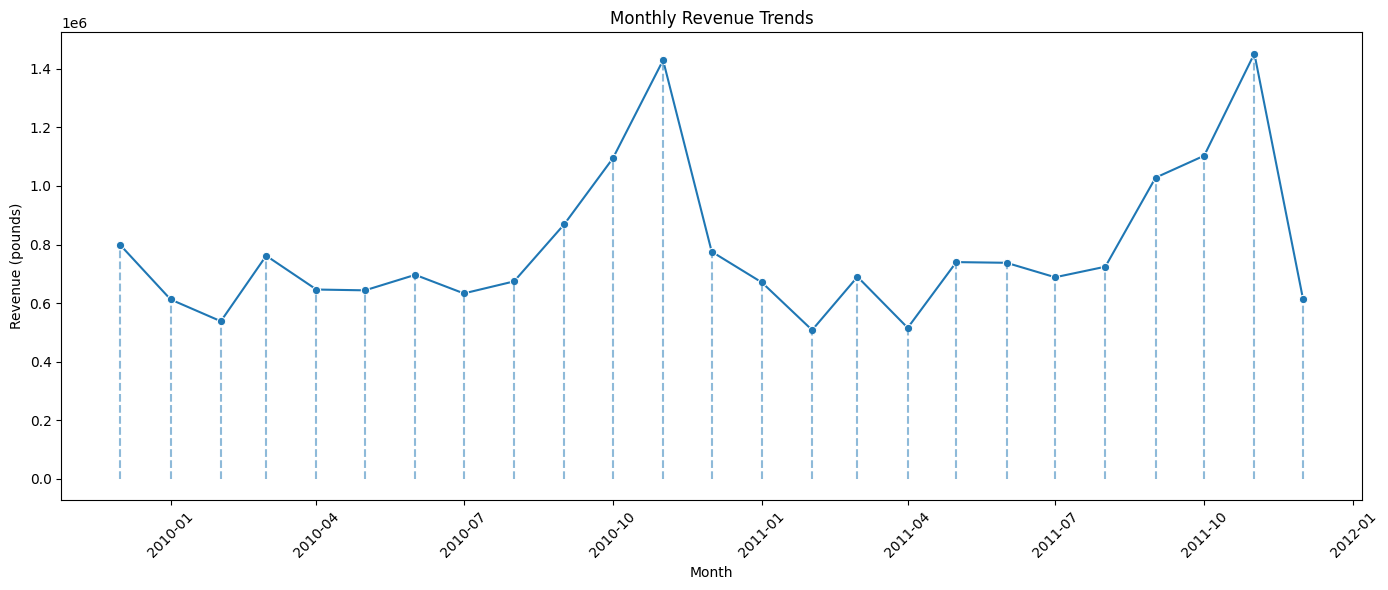

Total Revenue: 19642692.0


In [319]:
# Monthly revenue trends

sales_all['InvoiceDate'] = pd.to_datetime(sales_all['InvoiceDate'])

sales_data = sales_all[
    (sales_all['Quantity'] > 0) &
    (sales_all['Price'] > 0) &
    (~sales_all['Invoice'].astype(str).str.startswith('C', na=False))
].copy()

sales_data['Revenue'] = sales_data['Quantity'] * sales_data['Price']
sales_data['YearMonth'] = sales_data['InvoiceDate'].dt.to_period('M')

monthly_revenue = sales_data.groupby('YearMonth')['Revenue'].sum().reset_index()
monthly_revenue['YearMonth'] = monthly_revenue['YearMonth'].dt.to_timestamp()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_revenue, x='YearMonth', y='Revenue', marker='o')

plt.title('Monthly Revenue Trends')
plt.xlabel('Month')
plt.ylabel('Revenue (pounds)')
plt.xticks(rotation=45)

plt.vlines(
    monthly_revenue['YearMonth'],
    ymin=0,
    ymax=monthly_revenue['Revenue'],
    linestyle='--',
    alpha=0.5
)

plt.tight_layout()
plt.show()

print(f"Total Revenue: {sales_data['Revenue'].sum().round(0)}")

Data ends on 2011-12-09 -> the last month is NOT complete and is excluded from the lines below


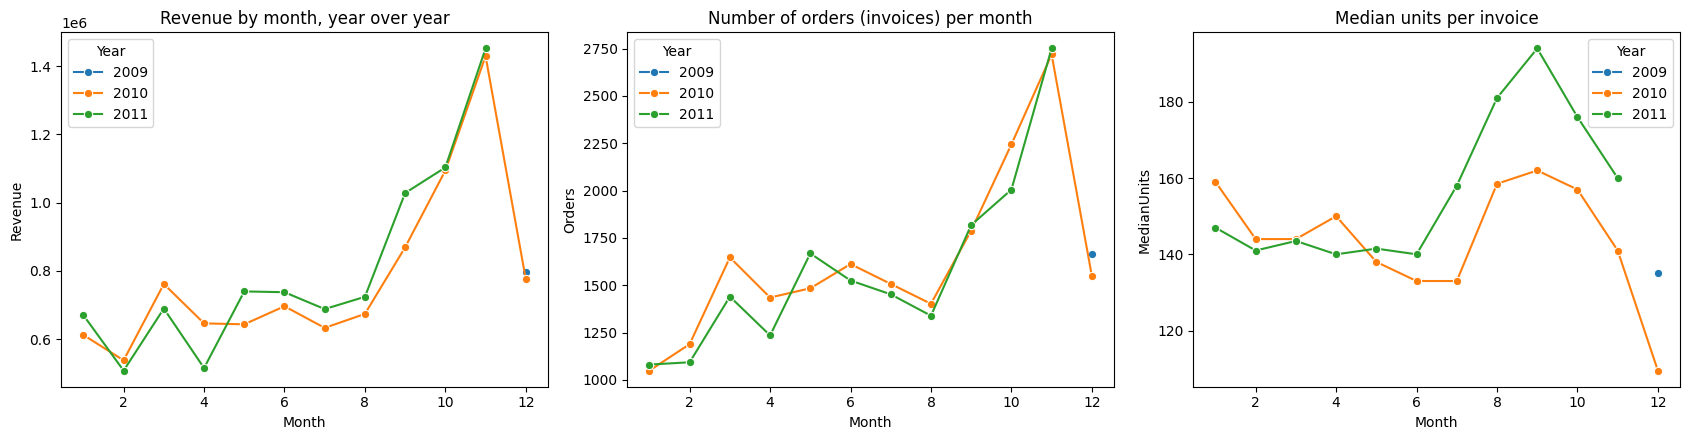

               Revenue  Orders  MedianUnits    AOV
InvoiceDate                                       
2009-12-01    797738.0    1666        135.0  479.0
2010-01-01    612271.0    1049        159.0  584.0
2010-02-01    537894.0    1189        144.0  452.0
2010-03-01    761666.0    1647        144.0  462.0
2010-04-01    646233.0    1435        150.0  450.0
2010-05-01    643474.0    1484        138.0  434.0
2010-06-01    696439.0    1612        133.0  432.0
2010-07-01    632984.0    1507        133.0  420.0
2010-08-01    674037.0    1402        158.0  481.0
2010-09-01    869224.0    1789        162.0  486.0
2010-10-01   1094358.0    2244        157.0  488.0
2010-11-01   1429553.0    2719        141.0  526.0
2010-12-01    775572.0    1550        110.0  500.0
2011-01-01    670362.0    1081        147.0  620.0
2011-02-01    507783.0    1093        141.0  465.0
2011-03-01    689708.0    1440        144.0  479.0
2011-04-01    515355.0    1235        140.0  417.0
2011-05-01    739914.0    1668 

In [288]:
# Year-over-year view, order size and average order value

monthly = sales_data.set_index('InvoiceDate').resample('MS')['Revenue'].sum().to_frame('Revenue')

inv = sales_data.groupby('Invoice').agg(InvoiceDate=('InvoiceDate', 'first'),
                                        Units=('Quantity', 'sum'),
                                        InvoiceValue=('Revenue', 'sum'))
monthly_inv = inv.set_index('InvoiceDate').resample('MS').agg(Orders=('Units', 'size'),
                                                               MedianUnits=('Units', 'median'),
                                                               AOV=('InvoiceValue', 'mean'))
monthly = monthly.join(monthly_inv)

last_day = sales_data['InvoiceDate'].max()
print('Data ends on', last_day.date(), '-> the last month is NOT complete and is excluded from the lines below')
monthly['Year'], monthly['Month'] = monthly.index.year, monthly.index.month
monthly_full = monthly[monthly.index < last_day.to_period('M').to_timestamp()]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.lineplot(data=monthly_full, x='Month', y='Revenue', hue='Year', marker='o', ax=ax[0], palette='tab10')
ax[0].set_title('Revenue by month, year over year')
sns.lineplot(data=monthly_full, x='Month', y='Orders', hue='Year', marker='o', ax=ax[1], palette='tab10')
ax[1].set_title('Number of orders (invoices) per month')
sns.lineplot(data=monthly_full, x='Month', y='MedianUnits', hue='Year', marker='o', ax=ax[2], palette='tab10')
ax[2].set_title('Median units per invoice')
plt.tight_layout()
plt.show()

print(monthly_full[['Revenue', 'Orders', 'MedianUnits', 'AOV']].round(0))

For most of the year monthly revenue stays at about 0.5 Million to 1.4 Million. From September it climbs, reaches about 0.8 Million in October, and peaks in November at about 1.4 Million in both years. The two November peaks are almost identical, so there is a strong seasonal cycle but no visible growth at the peak.

inisght: inventory should be planned for September to November.


### Product analysis

In [289]:
# Total unique products
total_unique_products = sales_all['StockCode'].nunique()
print(f"Total unique products: {total_unique_products}")

Total unique products: 4878


     StockCode                         Description  Quantity  Gross_Quantity
3555     84077   WORLD WAR 2 GLIDERS ASSTD DESIGNS    104435        106139.0
4286    85099B         JUMBO BAG RED WHITE SPOTTY      95544         96757.0
617      21212    PACK OF 72 RETRO SPOT CAKE CASES     93774         94884.0
4314    85123A  WHITE HANGING HEART T-LIGHT HOLDER     90566         94203.0
1441     22197             POPCORN HOLDER , SMALL      87695         88499.0
4004     84879       ASSORTED COLOUR BIRD ORNAMENT     79571         80082.0
114      17003                 BROCADE RING PURSE      69629         70369.0
1253     21977  PACK OF 60 PINK PAISLEY CAKE CASES     55842         56061.0
4140     84991         60 TEATIME FAIRY CAKE CASES     53678         54028.0
17       15036           ASSORTED COLOURS SILK FAN     43343         44272.0



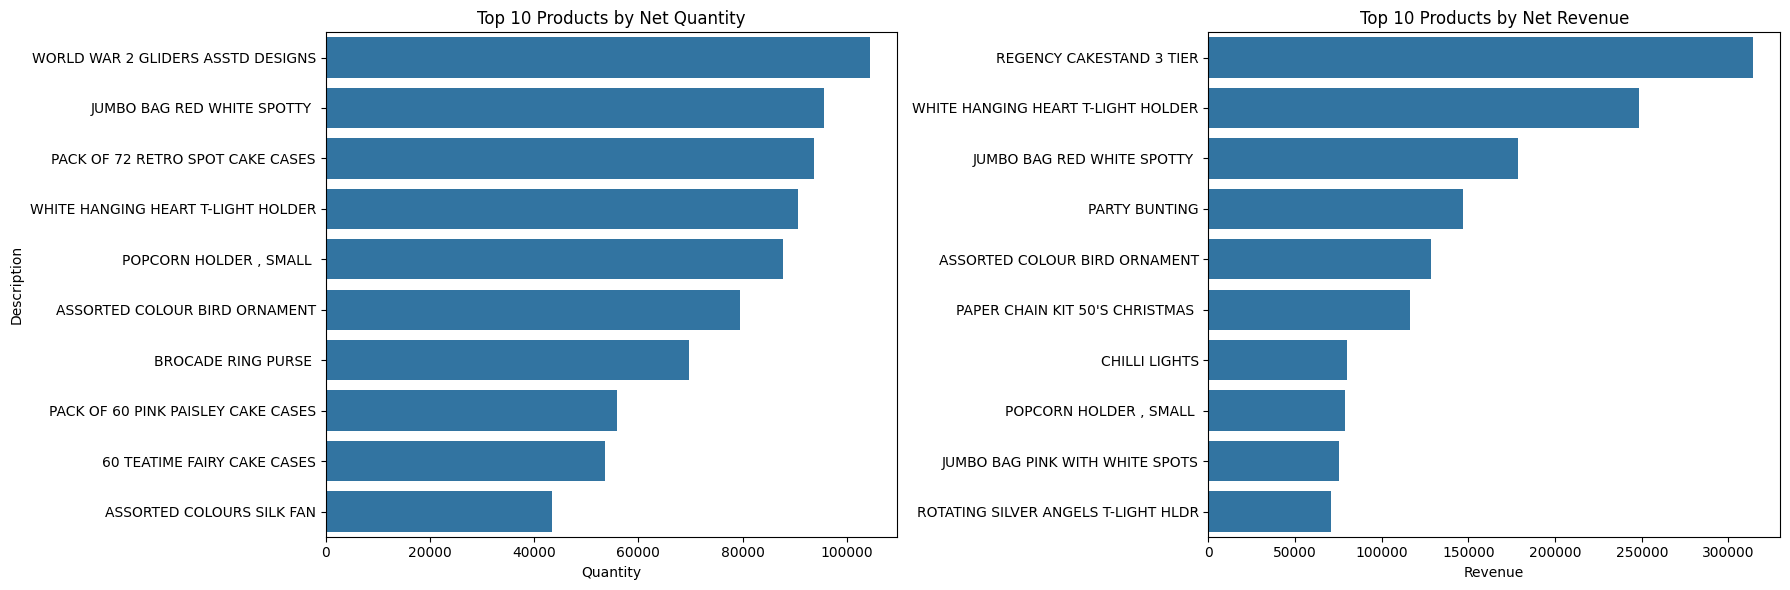

In [290]:
# Top product performers of all time and NET of returns (sales_net)
sales_per_product = (sales_net
                     .groupby('StockCode')
                     .agg(Quantity=('Quantity', 'sum'),
                          Revenue=('Revenue', 'sum'),
                          Description=('Description', 'first'))
                     .reset_index()
                     )

gross_qty = sales_all.groupby('StockCode')['Quantity'].sum().rename('Gross_Quantity')
sales_per_product = sales_per_product.join(gross_qty, on='StockCode')

top_10_products = sales_per_product.nlargest(10, 'Quantity')
top_10_revenue = sales_per_product.nlargest(10, 'Revenue')

print(top_10_products[['StockCode', 'Description', 'Quantity', 'Gross_Quantity']])
print("")

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.barplot(data=top_10_products, x='Quantity', y='Description', ax=ax[0])
ax[0].set_title('Top 10 Products by Net Quantity')
sns.barplot(data=top_10_revenue, x='Revenue', y='Description', ax=ax[1])
ax[1].set_title('Top 10 Products by Net Revenue')
ax[1].set_ylabel('')
plt.tight_layout()
plt.show()

Top products (quantity):  WORLD WAR 2 GLIDERS ASSTD DESIGNS,  JUMBO BAG RED WHITE SPOTTY, PACK OF 72 RETRO SPOT CAKE CASES, etc.

top products (revenue): REGENCY CAKESTAND 3 TIER, WHITE HANGING HEART T-LIGHT, JUMBO BAG REG WHITE SPOTTY

In [291]:
# Top product performers per seasons

season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Spring', 4: 'Spring', 5: 'Spring',
    6: 'Summer', 7: 'Summer', 8: 'Summer',
    9: 'Autumn', 10: 'Autumn', 11: 'Autumn'
}

sales_data['Season'] = sales_data['InvoiceDate'].dt.month.map(season_map)
sales_data['Year'] = sales_data['InvoiceDate'].dt.year

quartile_sales_per_product = (sales_data
                              .groupby(['Year','Season','StockCode'])
                              .agg(Quantity = ('Quantity', 'sum'),
                                   Description = ('Description', 'first'))
                              .reset_index()
                              )

top_10_products_pSeason = (quartile_sales_per_product.sort_values(['Season', 'Quantity'], ascending=[True, False])
                              .groupby(['Year','Season'])
                              .head(10)
                              )

print("Timeless items:\n")

timeless_item = (top_10_products_pSeason
                 .groupby('StockCode')
                 .agg(SeasonsAppeared=('Season', 'count'), TotalQuantity=('Quantity', 'sum'), Description=('Description', 'first'))
                 .reset_index()
                 .sort_values('SeasonsAppeared', ascending=False)
                 .head(5)
                 )

print(timeless_item)

def season_items(season):
  top_item = (top_10_products_pSeason[top_10_products_pSeason['Season'] == season]
                 .groupby('StockCode')
                 .agg(SeasonsAppeared=('Season', 'count'), TotalQuantity=('Quantity', 'sum'), Description=('Description', 'first'))
                 .reset_index()
                 .sort_values('SeasonsAppeared', ascending=False)
                 .head(5)
                 )

  return top_item

print("Winter items:\n")
winter_item = season_items('Winter')
print(winter_item)

print("Spring items:\n")
spring_item = season_items('Spring')
print(spring_item)

print("Summer items:\n")
summer_item = season_items('Summer')
print(summer_item)

print("Autumn items:\n")
autumn_item = season_items('Autumn')
print(autumn_item)

Timeless items:

   StockCode  SeasonsAppeared  TotalQuantity  \
9      21212                8          86763   
42    85123A                8          85136   
41    85099B                8          85940   
39     84879                7          66273   
35     84077                7          91945   

                           Description  
9     PACK OF 72 RETRO SPOT CAKE CASES  
42  WHITE HANGING HEART T-LIGHT HOLDER  
41             JUMBO BAG RED RETROSPOT  
39       ASSORTED COLOUR BIRD ORNAMENT  
35   WORLD WAR 2 GLIDERS ASSTD DESIGNS  
Winter items:

   StockCode  SeasonsAppeared  TotalQuantity  \
3      21212                3          23261   
19    85099B                3          19078   
20    85123A                3          26772   
16     84077                2          15415   
17     84879                2           9386   

                           Description  
3     PACK OF 72 RETRO SPOT CAKE CASES  
19         JUMBO BAG RED WHITE SPOTTY   
20  WHITE HANGING HEA

The analysis shows that items that generate high sales through out all seasons are:

* WHITE HANGING HEART T-LIGHT HOLDER  
* JUMBO BAG RED RETROSPOT  
* PACK OF 72 RETRO SPOT CAKE CASES  
* WORLD WAR 2 GLIDERS ASSTD DESIGNS  
* ASSORTED COLOUR BIRD ORNAMENT

Top 5 items sold during Winter:
* PACK OF 72 RETRO SPOT CAKE CASES  
* JUMBO BAG RED WHITE SPOTTY   
* WHITE HANGING HEART T-LIGHT HOLDER  
* WORLD WAR 2 GLIDERS ASSTD DESIGNS  
* ASSORTED COLOUR BIRD ORNAMENT  

Top 5 items sold during Spring:
* WHITE HANGING HEART T-LIGHT HOLDER  
* PACK OF 72 RETRO SPOT CAKE CASES

Top 5 items sold during Summer:
* ASSORTED COLOURS SILK FAN  
* PACK OF 72 RETRO SPOT CAKE CASES  
* ASSORTED COLOUR BIRD ORNAMENT  
* JUMBO BAG RED RETROSPOT  
* WHITE HANGING HEART T-LIGHT HOLDER

Top 5 items sold during Autumn:
* POPCORN HOLDER  
* WHITE HANGING HEART T-LIGHT HOLDER  
* ASSORTED COLOUR BIRD ORNAMENT  
* JUMBO BAG RED RETROSPOT  
* WORLD WAR 2 GLIDERS ASSTD DESIGNS

This shows that some products are constantly making high sales through out all seasons, and what items are seasonal. This gives insights on what items to stock at certain times and what items should always be stocked all year.

### Customer analysis

In [292]:
# Total unique customers in 2 years
unique_customers = sales_all['Customer ID'].nunique()

print(f"Total unique customers: {unique_customers}")

Total unique customers: 5852


In [293]:
# Domestic vs International customers
cust_countries = data['Country'].unique()
print(cust_countries)

['United Kingdom' 'France' 'USA' 'Belgium' 'Australia' 'EIRE' 'Germany'
 'Portugal' 'Japan' 'Denmark' 'Nigeria' 'Netherlands' 'Poland' 'Spain'
 'Channel Islands' 'Italy' 'Cyprus' 'Greece' 'Norway' 'Austria' 'Sweden'
 'United Arab Emirates' 'Finland' 'Switzerland' 'Unspecified' 'Malta'
 'Bahrain' 'RSA' 'Bermuda' 'Hong Kong' 'Singapore' 'Thailand' 'Israel'
 'Lithuania' 'West Indies' 'Lebanon' 'Korea' 'Brazil' 'Canada' 'Iceland'
 'Saudi Arabia' 'Czech Republic' 'European Community']


       Countries  CustCount
0       Domestic       5334
1  International        530


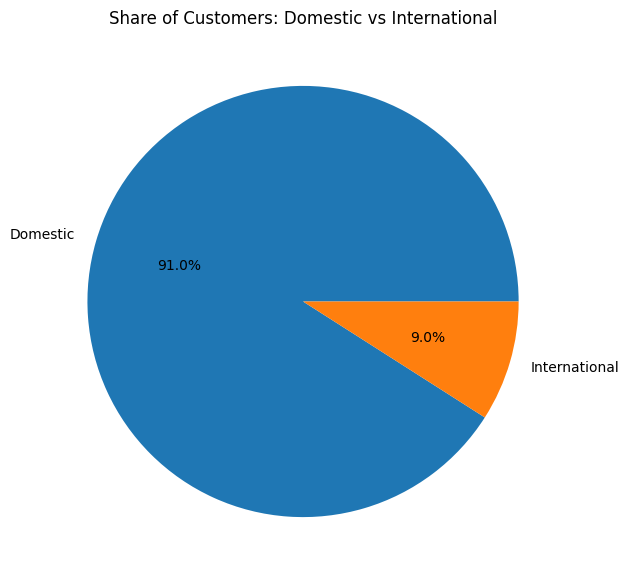

In [294]:
unique_customers_perCountries = sales_all.groupby('Country')['Customer ID'].nunique().reset_index()

unique_customers_perCountries.columns = ["Countries", "CustCount"]

cust_international_count = unique_customers_perCountries[unique_customers_perCountries["Countries"] != "United Kingdom"]["CustCount"].sum()
cust_domestic_count = unique_customers_perCountries[unique_customers_perCountries["Countries"] == "United Kingdom"]["CustCount"].sum()

cust_count = pd.DataFrame({
    'Countries': ['Domestic', 'International'],
    'CustCount': [cust_domestic_count, cust_international_count]
})

print(cust_count)

plt.figure(figsize=(7, 7))
plt.pie(cust_count['CustCount'], labels=cust_count['Countries'], autopct='%1.1f%%')
plt.title('Share of Customers: Domestic vs International')
plt.show()

In [295]:
region = np.where(sales_all['Country'] == 'United Kingdom', 'Domestic', 'International')
rev_by_region = sales_all.groupby(region)['Revenue'].sum()

print((rev_by_region / rev_by_region.sum()).round(3))

Domestic         0.855
International    0.145
Name: Revenue, dtype: float64


91% are from the UK and the other 9% are International.

International customers account for 14.5% of revenue and the domestic contributes to most of the sales, 85.5%

# Customer Segmentation (LRFM, using K-means)

L = Length. Current date minus the customer's earliest InvoiceDate

R = Recency. Current date minus the customer's latest InvoiceDate

F = Frequency. The total invoice a customer make

M = Monetary. Total of money spent per customer

## Calculating LRFM

In [296]:
from sklearn.preprocessing import StandardScaler

# the date of the last invoice
snapshot_date = data_lrfm['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

# L, R and F use purchases only, M is NET of returns (cancellations are negative revenue)
purchases_lrfm = data_lrfm[~data_lrfm['IsCancel']]
g_buy = purchases_lrfm.groupby('Customer ID')

lrfm = pd.DataFrame({
    'Length': (snapshot_date - g_buy['InvoiceDate'].min()).dt.days,
    'Recency': (snapshot_date - g_buy['InvoiceDate'].max()).dt.days,
    'Frequency': g_buy['Invoice'].nunique(),
    'Monetary': data_lrfm.groupby('Customer ID')['Revenue'].sum()
}).dropna().reset_index()

# Customers that spend 0 or negative
lrfm = lrfm[lrfm['Monetary'] > 0].reset_index(drop=True)

print(f"Length skewness: {lrfm['Length'].skew():.2f}")
print(f"Recency skewness: {lrfm['Recency'].skew():.2f}")
print(f"Frequency skewness: {lrfm['Frequency'].skew():.2f}")
print(f"Monetary skewness: {lrfm['Monetary'].skew():.2f}")

Length skewness: -0.62
Recency skewness: 0.89
Frequency skewness: 12.04
Monetary skewness: 25.33


There are skewness on every feature (LRFM), so we can use Logarithmic transformation to handle this skweness.

Since K-means defines clusters using by calculating averages (centroids), the algorithm is sensitive to outlier. If skewness is ignored, the defined segment will be defined poorly.

In [297]:
# Handling skewness
lrfm_log = pd.DataFrame()
lrfm_log['Customer ID'] = lrfm['Customer ID']
lrfm_log['Length_Log'] = np.log1p(lrfm['Length'])
lrfm_log['Recency_Log'] = np.log1p(lrfm['Recency'])
lrfm_log['Frequency_Log'] = np.log1p(lrfm['Frequency'])
lrfm_log['Monetary_Log'] = np.log1p(lrfm['Monetary'])

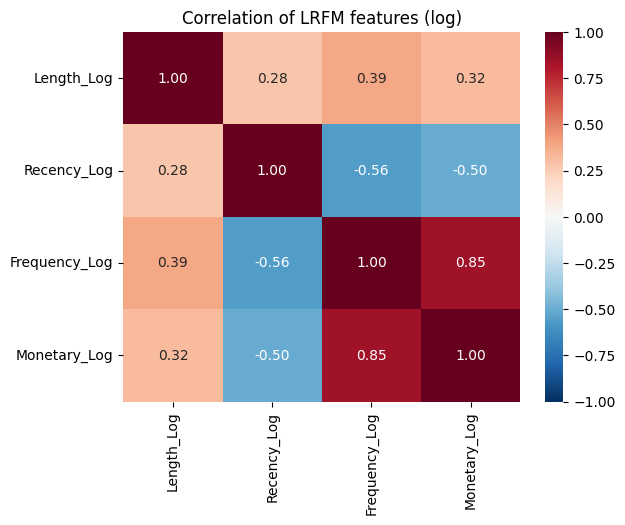

In [298]:
lrfm_log_features = ['Length_Log', 'Recency_Log', 'Frequency_Log', 'Monetary_Log']
sns.heatmap(lrfm_log[lrfm_log_features].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlation of LRFM features (log)')
plt.show()

1. Frequency and Monetary have a strong positive correlation (0.85), meaning that customers who purchase more frequently also tend to generate higher monetary value.
2. Recency has medium negative correlations with Frequency (-0.56) and Monetary (-0.50), meaning that customers who purchased more recently tend to have higher purchase frequency and spending.
3. Length has relatively weak-to-moderate positive relationships with the other LRFM features.

In [299]:
lrfm_log.describe()

,Customer ID,Length_Log,Recency_Log,Frequency_Log,Monetary_Log
count,5852.000000,5852.000000,5852.000000,5852.000000,5852.000000
mean,15319.707109,5.923454,4.426430,1.547149,6.808344
std,1714.929942,0.891401,1.594255,0.807752,1.380777
min,12346.000000,0.000000,0.000000,0.693147,1.373716
25%,13837.750000,5.743003,3.258097,0.693147,5.830635
50%,15320.500000,6.272877,4.564348,1.386294,6.753461
75%,16802.250000,6.502790,5.940171,2.079442,7.715137
max,18287.000000,6.605298,6.605298,5.924256,13.272485


Feature scalling is appropriate for this case, since each of the features are measured using different units.

This is especially important for K-Means, because the algorithm uses euclidian distance to group their clusters. Having a standardize scale accross features would allow the features to have similar influence during the clustering process.

In [300]:
# Feature scaling
scaler = StandardScaler()
scaled_features = ['Length_Log', 'Recency_Log', 'Frequency_Log', 'Monetary_Log']

lrfm_scaled = scaler.fit_transform(lrfm_log[scaled_features])
lrfm_scaled = pd.DataFrame(lrfm_scaled, columns=scaled_features, index=lrfm_log.index)
lrfm_scaled.insert(0, 'Customer ID', lrfm['Customer ID'])

print(lrfm_scaled)

      Customer ID  Length_Log  Recency_Log  Frequency_Log  Monetary_Log
0         12346.0    0.617549     0.853429      -0.199156      3.221509
1         12347.0    0.090240    -2.087559       0.804865      1.226396
2         12348.0    0.180681    -0.060031       0.302855      0.438825
3         12349.0    0.512348    -0.929662      -0.199156      1.015631
4         12350.0   -0.206054     0.823880      -1.057348     -0.811217
...           ...         ...          ...            ...           ...
5847      18283.0    0.636434    -1.907095       1.966546      0.780583
5848      18284.0    0.162647     1.030033      -1.057348     -0.569055
5849      18285.0    0.639834     1.296844      -1.057348     -0.632632
5850      18286.0    0.741971     1.092193      -0.555338      0.232134
5851      18287.0    0.477587    -0.417303       0.659037      1.099950

[5852 rows x 5 columns]


In [301]:
lrfm_scaled[scaled_features]

,Length_Log,Recency_Log,Frequency_Log,Monetary_Log
0,0.617549,0.853429,-0.199156,3.221509
1,0.090240,-2.087559,0.804865,1.226396
2,0.180681,-0.060031,0.302855,0.438825
3,0.512348,-0.929662,-0.199156,1.015631
4,-0.206054,0.823880,-1.057348,-0.811217
...,...,...,...,...
5847,0.636434,-1.907095,1.966546,0.780583
5848,0.162647,1.030033,-1.057348,-0.569055
5849,0.639834,1.296844,-1.057348,-0.632632
5850,0.741971,1.092193,-0.555338,0.232134


In [302]:
lrfm_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5852 entries, 0 to 5851
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    5852 non-null   float64
 1   Length_Log     5852 non-null   float64
 2   Recency_Log    5852 non-null   float64
 3   Frequency_Log  5852 non-null   float64
 4   Monetary_Log   5852 non-null   float64
dtypes: float64(5)
memory usage: 228.7 KB


## Determining number of clusters

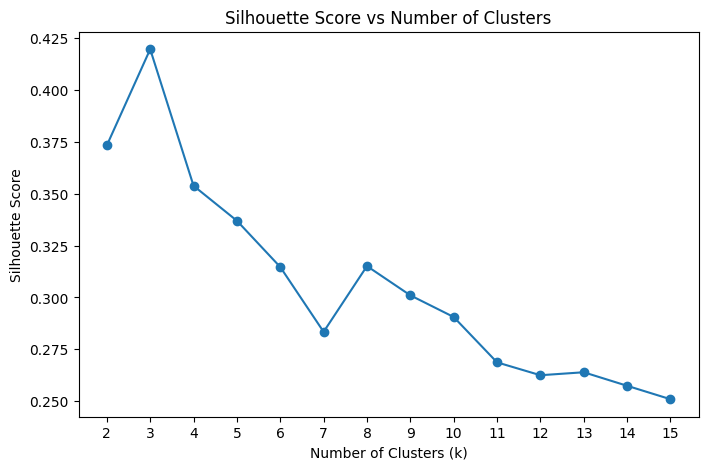

In [303]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []
for i in range(2,16):
  model = KMeans(n_clusters=i, random_state=42)
  cluster_labels = model.fit_predict(lrfm_scaled[scaled_features])

  score = silhouette_score(lrfm_scaled[scaled_features], cluster_labels)
  silhouette_scores.append(score)

plt.figure(figsize=(8,5))
plt.plot(range(2,16), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2,16))
plt.title('Silhouette Score vs Number of Clusters')

plt.show()

From this, we know that the optimal clusters or K for K-means is 3, since it achieve the highest silhouette score. Any number above 3 reduces the clustering quality and fail to capture the finer structure of the data.

Using the silhouette method gives a more objective judgment, since it is mathematical.

## K-means

In [304]:
# The model

model = KMeans(n_clusters=3, random_state=42)
model.fit(lrfm_scaled[scaled_features])

KMeans(n_clusters=3, random_state=42)

In [305]:
# Predict the Cluster

cluster_labels = model.labels_

lrfm_scaled['clusters'] = cluster_labels

lrfm_scaled_k_means = pd.DataFrame(lrfm_scaled).copy()
lrfm_scaled_k_means['clusters'] = cluster_labels

# Check the Result
print(lrfm_scaled_k_means['clusters'].value_counts())

clusters
2    2925
1    2068
0     859
Name: count, dtype: int64


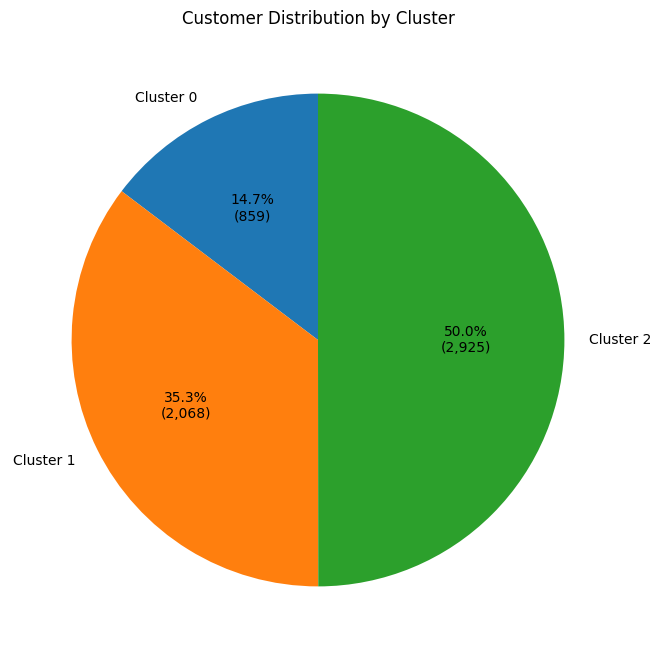

In [314]:
# Customer proportions

cluster_counts = lrfm_scaled_k_means['clusters'].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    cluster_counts,
    labels=[f'Cluster {cluster}' for cluster in cluster_counts.index],
    autopct=lambda pct: f'{pct:.1f}%\n({int(round(pct/100 * cluster_counts.sum())):,})',
    startangle=90
)

plt.title('Customer Distribution by Cluster')
plt.show()

The information above state the number of customers in each clusters. There the biggest cluster is cluster 2, with a total of 2.925 customers (50%), followed by cluster 1 (35.3%) and 0 (14.7%).

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


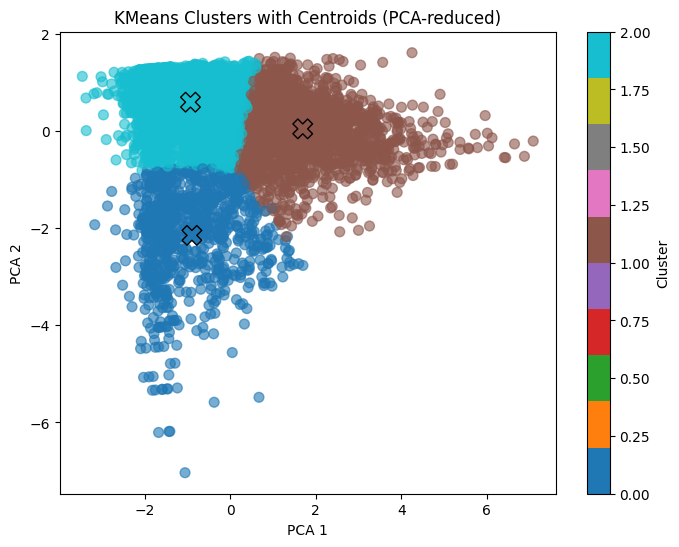

In [306]:
# Visuallizing the clusters
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(lrfm_scaled_k_means.drop(['clusters','Customer ID'], axis=1))
centers = pca.transform(model.cluster_centers_)

# Plot data points
plt.figure(figsize=(8,6))
plt.scatter(reduced_data[:,0], reduced_data[:,1],
            c=lrfm_scaled['clusters'], cmap='tab10', s=50, alpha=0.6)

# Plot centroids
plt.scatter(centers[:,0], centers[:,1],
            c=range(model.n_clusters), cmap='tab10',
            marker='X', s=200, edgecolor='black')

plt.title("KMeans Clusters with Centroids (PCA-reduced)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label='Cluster')
plt.show()

From the visualization above, it is apparent there are a pretty good cohesion, however the seperatation between clusters could be improved since the clusters are not fully separated.

This indicate that more features should be added to seperate the clusters better. Feature engineering could be the next step for this.   

## Cluster Analysis

In [307]:
cluster_summary = lrfm_scaled.groupby('clusters').agg({
  'Length_Log': 'mean',
  'Recency_Log': 'mean',
  'Frequency_Log': 'mean',
  'Monetary_Log': ['mean', 'count']
}).round(1)

display(cluster_summary)

Length_Log Recency_Log Frequency_Log Monetary_Log      
               mean        mean          mean         mean count
clusters                                                        
0              -2.1        -0.7          -0.7         -0.5   859
1               0.5        -0.8           1.1          1.0  2068
2               0.3         0.7          -0.6         -0.5  2925

Meaning of value:
1. Negative: below dataset average
2. Positive: above dataset average

Rule of thumb:
1. positive is good for Length, Frequency, and Monetary
2. negative is food for Recency

Conclusion
1. Cluster 0: New customers
    * Characteristics: Low Length, Low Recency, Low Frequency, Low Monetary
    * Meaning: brand new customers who spend a small amount recently.
2. Cluster 1: Loyal high value customer
    * Characteristics: High Length, Low Recency, High Frequency, High Monetary
    * Meaning: Loyal high-value customers who bought recently.
3. Cluster 2: Dormant customers
    * Characteristics: Medium Length, High Recency, Low Frequency, Low Monetary
    * Meaning: last purchase long ago, low F and M.    

## Customer Segmentation Analysis

In [308]:
data_clustered = pd.merge(data, lrfm_scaled[['Customer ID', 'clusters']], on='Customer ID', how='left')

In [309]:
def bar_plot_clusters(cluster, dataset, title, x, y):
  if cluster != -1:
    dataset = dataset[dataset['clusters'] == cluster]

  plt.figure(figsize=(10, 6))
  sns.barplot(data=dataset, x=x, y=y)
  plt.xlabel(x)
  plt.ylabel(y)
  plt.title(title)
  plt.show()

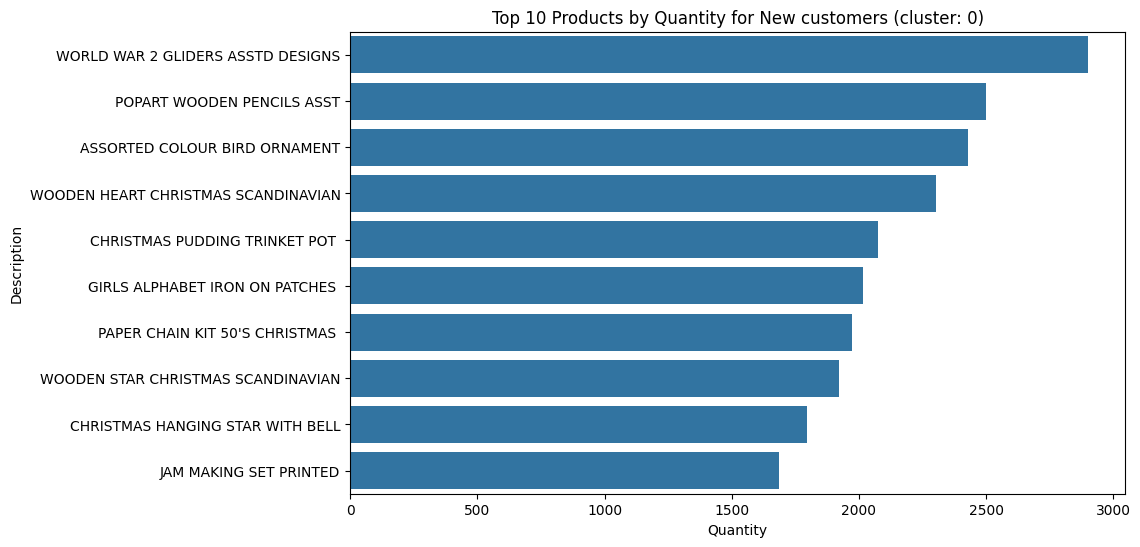

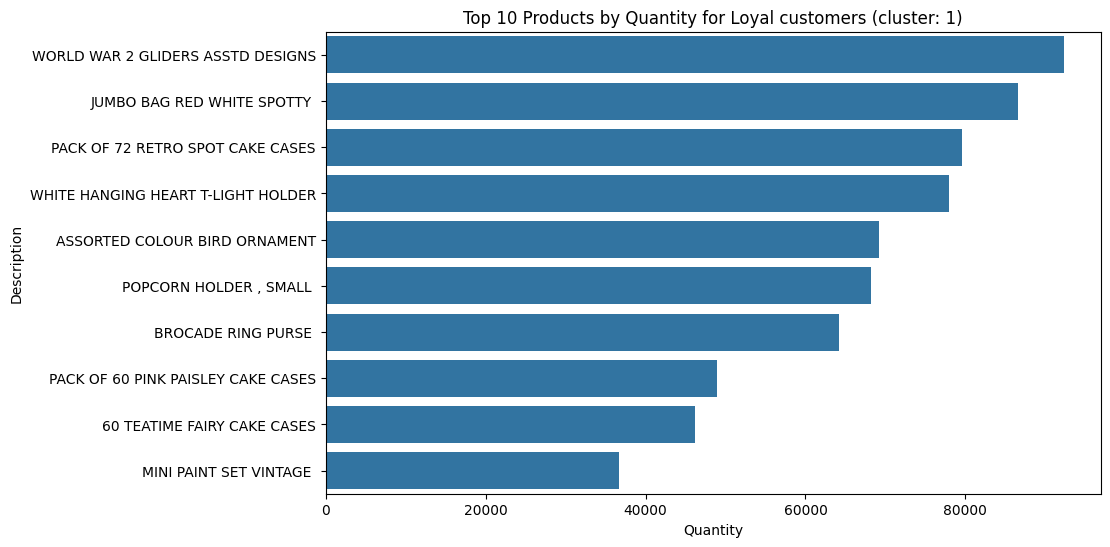

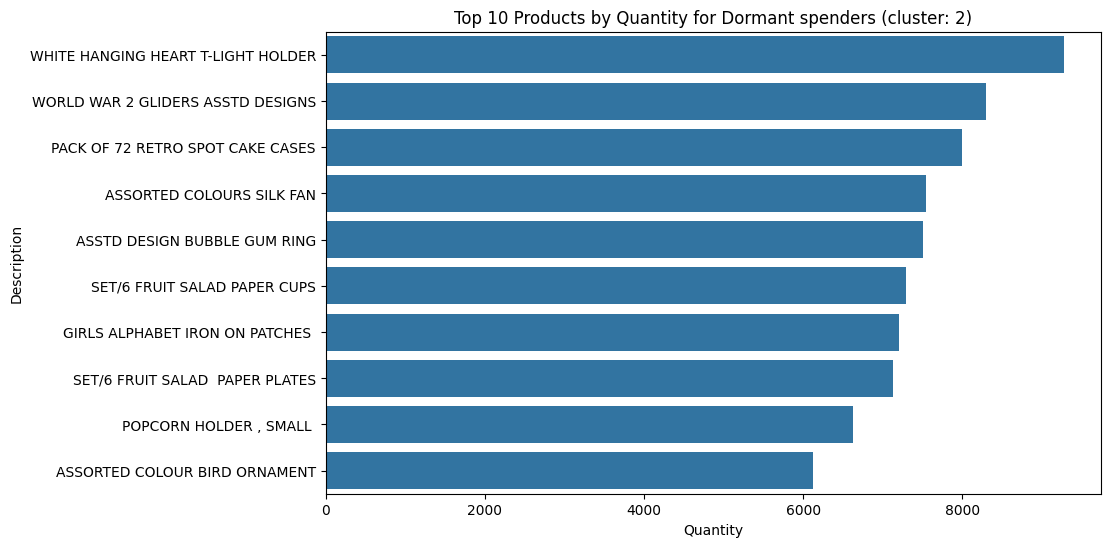

In [315]:
# Favorite products per customer segments
product_sales_per_clusters = (data_clustered
                              .groupby(['clusters', 'StockCode'])
                              .agg(Quantity = ('Quantity', 'sum'),
                                   Description = ('Description', 'first'))
                              .reset_index()
                              )

top10_product_sales_per_clusters = (product_sales_per_clusters.sort_values(['Quantity', 'clusters'], ascending=[False, True])
                                    .groupby('clusters')
                                    .head(10)
                                    )


bar_plot_clusters(0, top10_product_sales_per_clusters, "Top 10 Products by Quantity for New customers (cluster: 0)", 'Quantity', 'Description')
bar_plot_clusters(1, top10_product_sales_per_clusters, "Top 10 Products by Quantity for Loyal customers (cluster: 1)", 'Quantity', 'Description')
bar_plot_clusters(2, top10_product_sales_per_clusters, "Top 10 Products by Quantity for Dormant spenders (cluster: 2)", 'Quantity', 'Description')

this shows what products each customer likes most  

In [311]:
# Average unique product of customer segments (clusters) per invoice

unique_products_per_invoice = (data_clustered.groupby('Invoice')
                               .agg(UniqueProducts=('StockCode', 'nunique'), clusters=('clusters', 'first'))
                               .reset_index()
                               )

avg_unique_products_per_invoice = unique_products_per_invoice.groupby('clusters')['UniqueProducts'].mean().reset_index()
avg_unique_products_per_invoice.columns = ['clusters', 'AverageUniqueProducts']

print(avg_unique_products_per_invoice)

   clusters  AverageUniqueProducts
0       0.0              20.667852
1       1.0              17.771778
2       2.0              16.051605


1. New customers have an average of 20-21 unique products per invoice
1. Loyal customers have an average of 17-18 unique products per invoice
1. Dormant customers have an average of 16-17 unique products per invoice

    clusters               Country  CountriesCount
0        0.0               Austria               1
1        0.0               Belgium               4
2        0.0                Canada               1
3        0.0       Channel Islands               1
4        0.0                Cyprus               1
..       ...                   ...             ...
84       2.0                   USA               5
85       2.0  United Arab Emirates               3
86       2.0        United Kingdom            2692
87       2.0           Unspecified               4
88       2.0           West Indies               1

[89 rows x 3 columns]


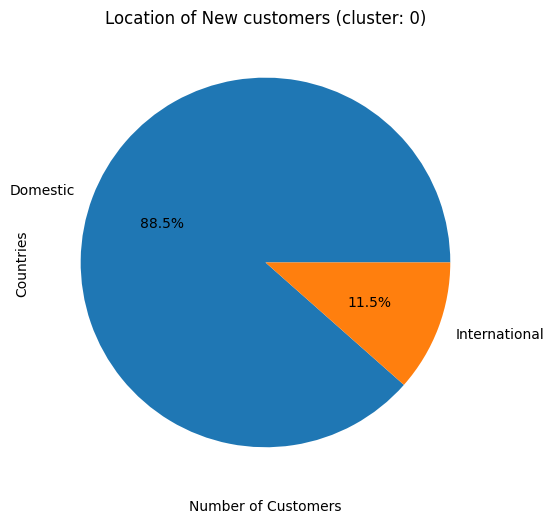

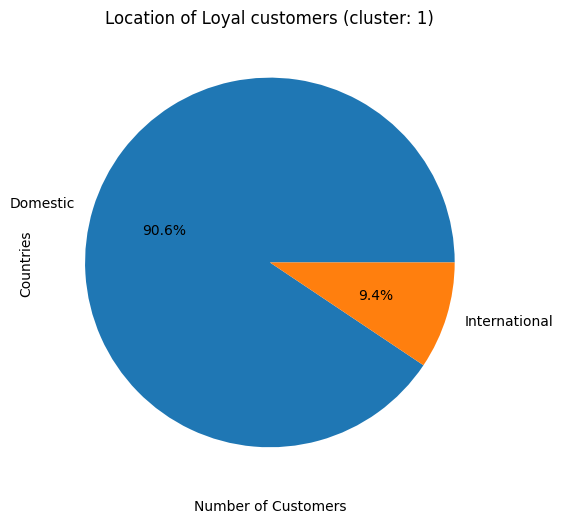

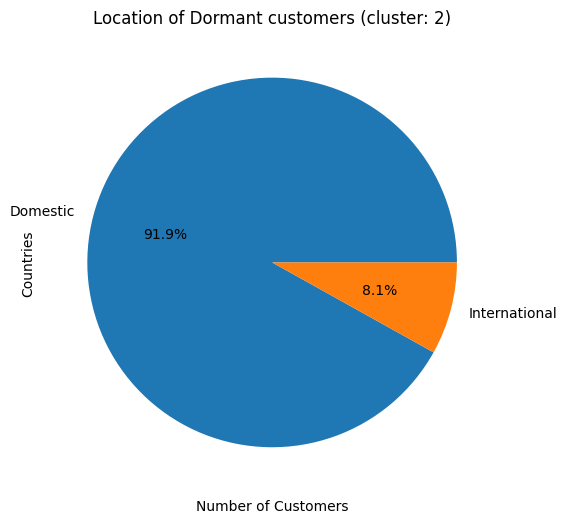

In [316]:
# Location of each customer segments (clusters)
countries_count_per_cluster = (data_clustered.groupby(['clusters', 'Country'])['Customer ID']
                               .nunique()
                               .reset_index(name='CountriesCount'))

print(countries_count_per_cluster)

def pie_plot_clusters(cluster, dataset, title):
  countries_count_domestic = dataset[(dataset['clusters'] == cluster) & (dataset['Country'] == 'United Kingdom')]['CountriesCount'].sum()
  countries_count_international = dataset[(dataset['clusters'] == cluster) & (dataset['Country'] != 'United Kingdom')]['CountriesCount'].sum()

  countries = ['Domestic', 'International']
  countries_count = [countries_count_domestic, countries_count_international]

  plt.figure(figsize=(10, 6))
  plt.pie(countries_count, labels=countries, autopct='%1.1f%%')
  plt.xlabel('Number of Customers')
  plt.ylabel('Countries')
  plt.title(title)
  plt.show()

pie_plot_clusters(0, countries_count_per_cluster, "Location of New customers (cluster: 0)")
pie_plot_clusters(1, countries_count_per_cluster, "Location of Loyal customers (cluster: 1)")
pie_plot_clusters(2, countries_count_per_cluster, "Location of Dormant customers (cluster: 2)")

The UK share of customers is 11.5% for new, meanwhile 9.4% for loyal and 8.1% for dormant customers, close to the overall 9%.

This shows that country is not what makes a customer loyal or dormant

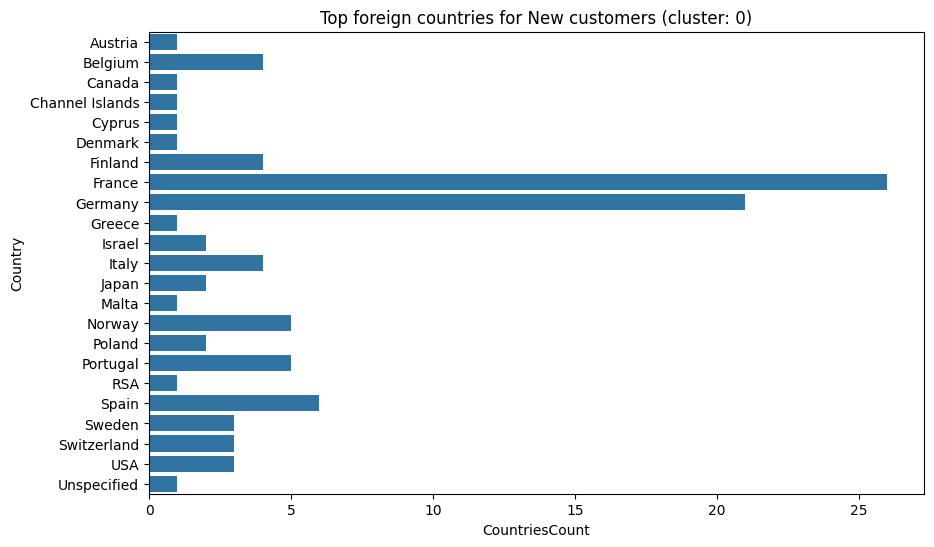

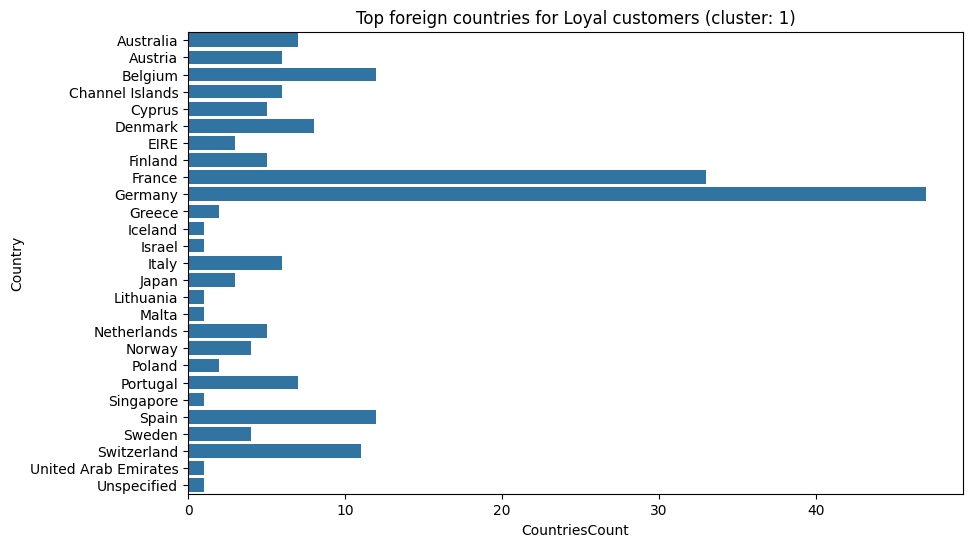

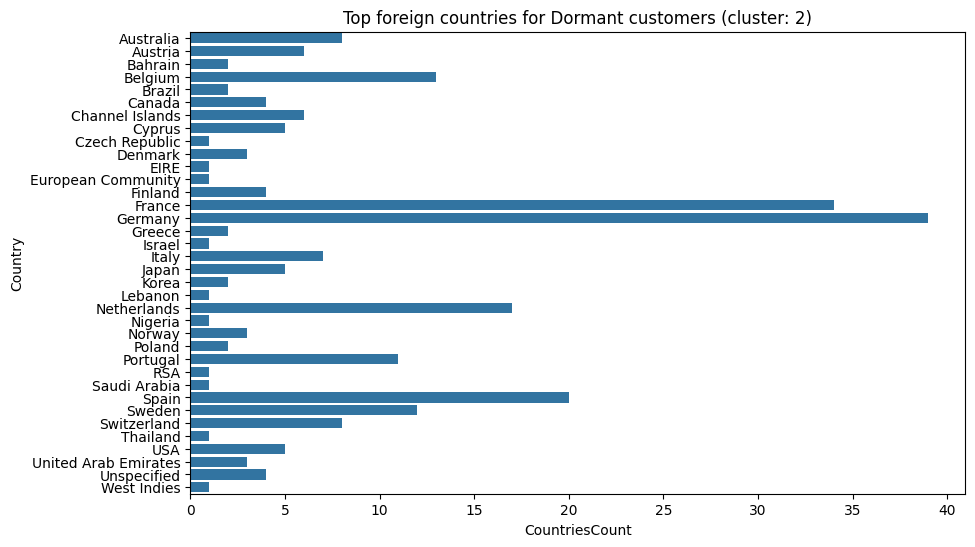

In [317]:
# International customers

bar_plot_clusters(0, countries_count_per_cluster[countries_count_per_cluster['Country'] != 'United Kingdom'], "Top foreign countries for New customers (cluster: 0)", 'CountriesCount', 'Country')
bar_plot_clusters(1, countries_count_per_cluster[countries_count_per_cluster['Country'] != 'United Kingdom'], "Top foreign countries for Loyal customers (cluster: 1)", 'CountriesCount', 'Country')
bar_plot_clusters(2, countries_count_per_cluster[countries_count_per_cluster['Country'] != 'United Kingdom'], "Top foreign countries for Dormant customers (cluster: 2)", 'CountriesCount', 'Country')


Among international customers, France and Germany dominates the International customer. However, what is interesting is that Spain and the Netherlands made up a good chuck of the Dormant customers

# Findings and Recommendation

### Key Findings
1. The data needed cleaning: about 0.57% of rows are non-product codes, and 22.77% of data has no Customer ID.
2. Revenue rises sharply from September, peaks in November, and the November peak did not grow from 2010 to 2011. Buyers appear to be resellers stocking up before Christmas.
3. Customers fall into three groups: loyal high-value (35.3% of customers), dormant (50% of customers) and new (14.7% of customers).
4. Loyal customers buy in bulk, with export concentrated in France and Germany. New customers lean towards World War 2 Gliders and Popart wooden pencils. Country does not separate loyal from lapsed customers.

### Reflection

Customers are summarised with four interpretable behaviours (how long, how recently, how often, how much). Log transformation and standardisation were applied because the features are heavily skewed and on different scales. K-means was chosen as a simple, explainable baseline instead of a more complex model.

### Limitations
1. Customers form a continuum, so segment borders are a convenience, not a natural boundary.
2. The data covers one UK wholesaler between Dec 2009 and Dec 2011, so results may not hold today.
3. Rows without Customer ID (about 23%) are invisible to the segmentation.
4. There is no product category, margin or cost data, so "value" means revenue, not profit.
5. The segments were not tested on later data.
6. The impact figures depend on assumed response rates.

### What could be improved
- Build segments on 2010 and check whether 2011 behaviour matches.
- Add return rate and product mix as features.
- Estimate customer lifetime value and churn probability.
- Add a cohort retention table. Forecast monthly demand for the Sep to Nov peak.

### AI use
I mainly use AI to help be guide with python syntaxes that are not familiar to me (e.g. .agg()) and bugs. I also use AI to provide a more clearer and goal oriented target for the topic, and use it as a guide.